# Исследовательский ноутбук прогнозированиz депозитов населения Беларуси
Помогают ли данные о новых депозитных договорах точнее прогнозировать остатки на счетах населения? Проверим это на статистике НБРБ: сравним простые прогнозы с Ridge, затем добавим показатели новых договоров и регуляторных условий. Рублёвые и валютные депозиты рассмотрим отдельно.
Есть важная оговорка: новый договор — не обязательно новые деньги. В статистику входят и продления вкладов.
Используем остатки за декабрь 2014 — август 2026 года, новые договоры — с января 2020 года. Этот период уже изучался при разработке моделей; здесь мы воспроизводим расчёты. Независимая проверка потребует новых данных.

In [10]:
from pathlib import Path
import pandas as pd

In [27]:
file_path = Path("data/broadmoney_ru.xlsx")
print("Файл найден:", file_path.exists())
excel_file = pd.ExcelFile(file_path)
excel_file.sheet_names

Файл найден: True


['2015',
 '2016',
 '2017',
 '2018',
 '2019',
 '2020',
 '2021',
 '2022',
 '2023',
 '2024',
 '2025',
 '2026']

In [71]:
def read_stock_year(excel_file, year):
    raw = pd.read_excel(excel_file, sheet_name=str(year), header=None)

    stocks = raw.iloc[[6, 10, 29, 32], 1:].T.copy()
    stocks.columns = [
        "byn_transfer",
        "byn_other",
        "fx_transfer_usd",
        "fx_other_usd",
    ]
    stocks = stocks.apply(pd.to_numeric, errors="raise")

    dates = pd.to_datetime(raw.iloc[3, 1:].values)
    stocks.index = dates.to_period("M") - 1
    stocks.index.name = "month"

    stocks["byn_stock_mln"] = (
        stocks["byn_transfer"] + stocks["byn_other"]
    )
    stocks["fx_stock_usd_mln"] = (
        stocks["fx_transfer_usd"] + stocks["fx_other_usd"]
    )

    return stocks

In [72]:
stocks_2016 = read_stock_year(excel_file, 2016)
stocks_2016.head()

,byn_transfer,byn_other,fx_transfer_usd,fx_other_usd,byn_stock_mln,fx_stock_usd_mln
month,,,,,,
2015-12,1405.9848,2614.4611,521.315,7691.459,4020.4459,8212.774
2016-01,1288.0616,2465.5978,419.011,7665.671,3753.6594,8084.682
2016-02,1235.0413,2428.7039,391.668,7549.098,3663.7452,7940.766
2016-03,1179.5471,2471.2406,376.209,7538.571,3650.7877,7914.780
2016-04,1349.7180,2494.9795,388.624,7445.861,3844.6975,7834.485


In [74]:
year_tables = []

for year in range(2015, 2027):
    year_stocks = read_stock_year(excel_file, year)
    year_tables.append(year_stocks)

stocks = pd.concat(year_tables).sort_index()

In [76]:
print("Размер:", stocks.shape)
print("Первый месяц:", stocks.index.min())
print("Последний месяц:", stocks.index.max())
print("Повторяющихся месяцев:", stocks.index.duplicated().sum())
print("Пропуски:")
print(stocks.isna().sum())

display(stocks.tail())

Размер: (141, 6)
Первый месяц: 2014-12
Последний месяц: 2026-08
Повторяющихся месяцев: 0
Пропуски:
byn_transfer        0
byn_other           0
fx_transfer_usd     0
fx_other_usd        0
byn_stock_mln       0
fx_stock_usd_mln    0
dtype: int64


,byn_transfer,byn_other,fx_transfer_usd,fx_other_usd,byn_stock_mln,fx_stock_usd_mln
month,,,,,,
2026-04,10932.757000,17023.781000,2673.642933,2398.987956,27956.538000,5072.630889
2026-05,11434.217000,17459.395000,2675.105812,2411.705682,28893.612000,5086.811494
2026-06,11768.758305,17862.671467,2656.852577,2360.831381,29631.429772,5017.683958
2026-07,12224.331068,18375.561653,2615.448830,2355.663044,30599.892721,4971.111873
2026-08,11885.148445,18939.671896,2599.715133,2314.293823,30824.820341,4914.008956


In [77]:
expected_months = pd.period_range(
    start="2014-12",
    end="2026-08",
    freq="M",
)

missing_months = expected_months.difference(stocks.index)
extra_months = stocks.index.difference(expected_months)

print("Отсутствующие месяцы:", missing_months)
print("Лишние месяцы:", extra_months)

assert stocks.index.is_unique
assert stocks.index.equals(expected_months)
assert stocks.notna().all().all()


Отсутствующие месяцы: PeriodIndex([], dtype='period[M]')
Лишние месяцы: PeriodIndex([], dtype='period[M]')


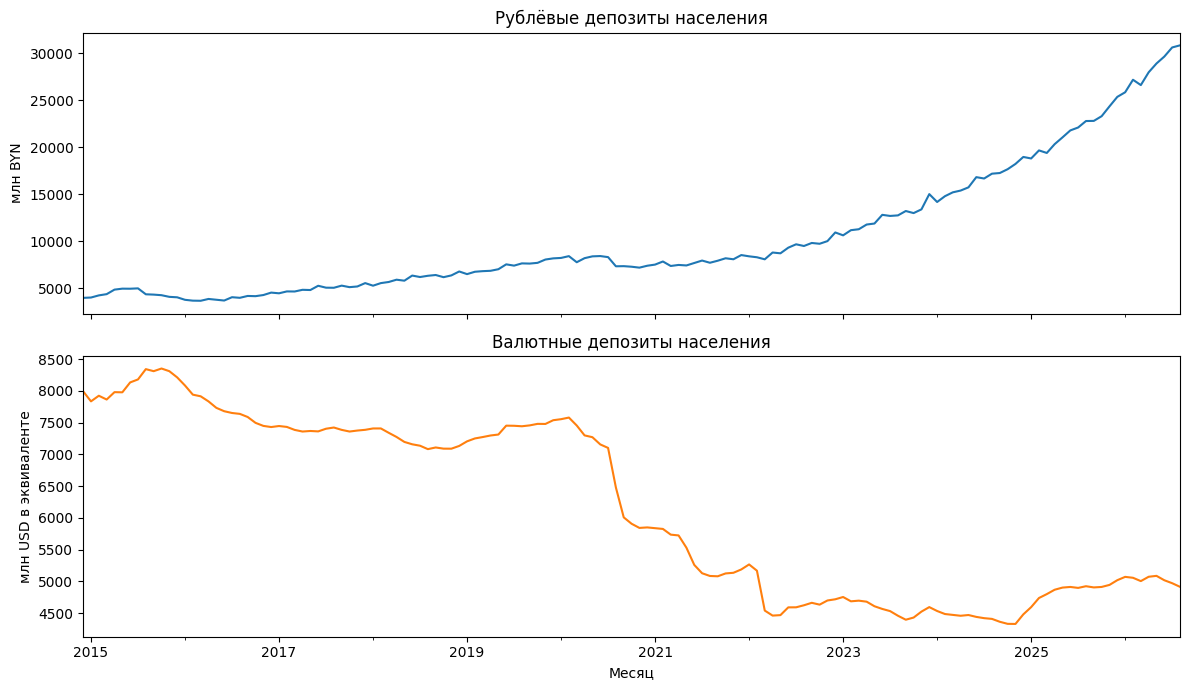

In [78]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

stocks["byn_stock_mln"].plot(ax=axes[0], color="tab:blue")
axes[0].set_title("Рублёвые депозиты населения")
axes[0].set_ylabel("млн BYN")

stocks["fx_stock_usd_mln"].plot(ax=axes[1], color="tab:orange")
axes[1].set_title("Валютные депозиты населения")
axes[1].set_ylabel("млн USD в эквиваленте")
axes[1].set_xlabel("Месяц")

plt.tight_layout()
plt.show()

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

stocks["byn_stock_mln"].plot(ax=axes[0], color="tab:blue")
axes[0].set_title("Рублёвые депозиты населения")
axes[0].set_ylabel("млн BYN")

stocks["fx_stock_usd_mln"].plot(ax=axes[1], color="tab:orange")
axes[1].set_title("Валютные депозиты населения")
axes[1].set_ylabel("млн USD в эквиваленте")
axes[1].set_xlabel("Месяц")

plt.tight_layout()
plt.show()

In [79]:
stock_changes = stocks[["byn_stock_mln", "fx_stock_usd_mln"]].diff()

stock_changes.head()

,byn_stock_mln,fx_stock_usd_mln
month,,
2014-12,NaN,NaN
2015-01,34.93555,-158.122
2015-02,227.62483,88.506
2015-03,132.27856,-59.733
2015-04,480.82123,116.278
